# Part 3 · Stable Diffusion: one change at a time


**Needs a GPU**: in Google Colab, choose *Runtime > Change runtime type > T4 GPU* before running anything.

In this lab part you use a real text-to-image model, **Stable Diffusion 1.5**. Everything you met in Labs 1 and 2 is inside it: a network that guesses noise, a generation loop with a number of steps, a seed, classifier-free guidance. Two things are new: the condition is a **sentence** (the prompt), and the generation happens in a **compressed latent space**, not on the pixels.


Run the cells in order, write your predictions, and fill in the **Your answer** cells.

## 1 · Load the model and generate a first image

The first cell installs the `diffusers` library (it may already be installed) and checks the GPU.

In [9]:
!pip install -q diffusers transformers accelerate
!pip install -U diffusers torchao

In [10]:
import time
import numpy as np
import torch
import matplotlib.pyplot as plt

device = 'cuda' if torch.cuda.is_available() else 'cpu'
dtype = torch.float16 if device == 'cuda' else torch.float32
if device == 'cpu':
    print('No GPU found. In Colab: Runtime > Change runtime type > T4 GPU, then run this cell again.')
else:
    print('GPU found:', torch.cuda.get_device_name(0))

GPU found: Tesla T4


The next cell downloads Stable Diffusion 1.5 (about 2 GB, 1 to 3 minutes) and selects the **DDIM** sampler in Lab part 1. You may see a message about `HF_TOKEN` or about a missing access token: you can ignore it, no account is needed for this model.

In [11]:
# Si l'import échoue à cause d'un conflit torchao/diffusers, exécutez d'abord : !pip install -U diffusers torchao
from diffusers import StableDiffusionPipeline, DDIMScheduler

MODEL_IDS = ['stable-diffusion-v1-5/stable-diffusion-v1-5', 'sd-legacy/stable-diffusion-v1-5']
pipe, last_error = None, None
for model_id in MODEL_IDS:
    for variant in ['fp16', None]:
        try:
            pipe = StableDiffusionPipeline.from_pretrained(model_id, torch_dtype=dtype, variant=variant)
            break
        except Exception as error:
            last_error = error
    if pipe is not None:
        break
if pipe is None:
    raise RuntimeError(f'The model could not be downloaded: {last_error}')

pipe.scheduler = DDIMScheduler.from_config(pipe.scheduler.config)   # the DDIM sampler (lecture slide 32)
pipe = pipe.to(device)
pipe.set_progress_bar_config(disable=True)
print('Model ready:', model_id)

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

Model ready: stable-diffusion-v1-5/stable-diffusion-v1-5


The function `make_image` below generates one image and measures how long it takes. Its settings are the ones you already know:

| Setting | Meaning |
|---|---|
| `prompt` | the sentence describing the image
| `seed` | fixes the random starting noise
| `guidance` | strength of classifier-free guidance
| `steps` | number of steps from pure noise to the image
| `negative_prompt` | a sentence to steer away from
| `randomness` | fresh noise at each step (DDPM style) or not (DDIM style)

In [12]:
LATENT_SIZE = pipe.unet.config.sample_size        # 64 for Stable Diffusion 1.5
LATENT_CHANNELS = pipe.unet.config.in_channels    # 4


def starting_noise(seed):
    """The random starting point of the generation, fixed by the seed (always drawn the same way)."""
    generator = torch.Generator('cpu').manual_seed(seed)
    noise = torch.randn((1, LATENT_CHANNELS, LATENT_SIZE, LATENT_SIZE), generator=generator)
    return noise.to(device, dtype)


def make_image(prompt, seed=0, guidance=7.5, steps=25, negative_prompt=None, randomness=False, randomness_seed=None):
    """Generate one image and measure how long it takes.
    guidance: strength of classifier-free guidance (1 = no amplification).
    randomness: if True, fresh noise is added at each step (DDPM style); if False, none (DDIM style)."""
    step_generator = torch.Generator(device).manual_seed(randomness_seed if randomness_seed is not None else seed + 1000)
    if device == 'cuda':
        torch.cuda.synchronize()
    start = time.perf_counter()
    result = pipe(prompt, num_inference_steps=steps, guidance_scale=guidance, negative_prompt=negative_prompt,
                  eta=1.0 if randomness else 0.0, latents=starting_noise(seed), generator=step_generator)
    if device == 'cuda':
        torch.cuda.synchronize()
    return result.images[0], time.perf_counter() - start


def show_row(images, titles, size=3.6):
    fig, axes = plt.subplots(1, len(images), figsize=(size * len(images), size + 0.5))
    axes = np.atleast_1d(axes)
    for ax, image, title in zip(axes, images, titles):
        ax.imshow(image)
        ax.set_title(title, fontsize=10)
        ax.axis('off')
    plt.show()

Let us generate the example of the lecture (slides 6 and 34).

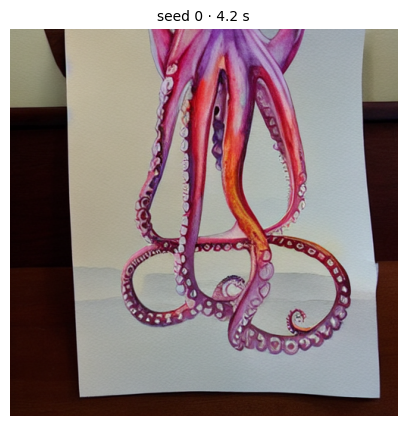

In [13]:
prompt = 'a watercolor painting of a chair that looks like an octopus'
image, seconds = make_image(prompt, seed=0)
show_row([image], [f'seed 0 · {seconds:.1f} s'], size=5)

## 2 · Change only the seed


Same prompt, same settings, four different seeds.

**Predict.** What will the four images have in common, and what will be different?

*Your answer:*

* What they have in common: The subject (an octopus-like chair) and the artistic style (watercolor painting).
* What will be different: The exact composition, posture of the tentacles, specific color splatters, and background details due to the different starting noise (seeds).


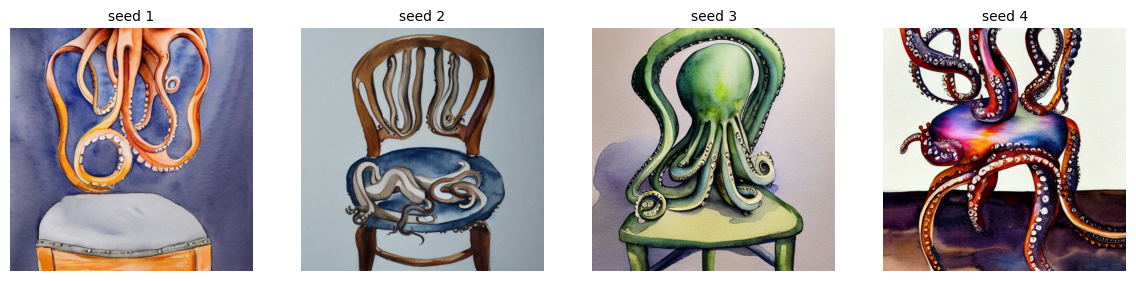

In [14]:
results = [make_image(prompt, seed=s) for s in [1, 2, 3, 4]]
show_row([r[0] for r in results], [f'seed {s}' for s in [1, 2, 3, 4]])

**Question 1.** What stays the same, and what changes from one seed to another? What is the role of the seed in the generation?

Your answer:

* What stays the same: The overall subject (an octopus-shaped chair) and the watercolor artistic style remain consistent across different seeds.
* What changes: The layout, composition, precise orientation/structure of the chair, specific watercolor splashes, and background details are completely different.
* Role of the seed: The seed determines the random starting noise (at step 0) in the latent space. Different starting noise forces the model to decode a completely different unique image while following the same semantic prompt.


## 3 · Change only the guidance


Same prompt, same seed, guidance 1, 3, 7.5 (the usual default) and 15. As in Lab part 2, guidance 1 means "follow the prompt without amplification". Note: in this library any value of 1 or less means "no amplification", so guidance 0 cannot be shown here.

**Predict.** How will the images change as the guidance increases? Will the generation time change?

Your answer:

* How the images will change:
  * Guidance 1: The image might lack contrast, look washed out, or not adhere well to the prompt because there is no guidance amplification.
  * Guidance 3 & 7.5: The image will align much better with the prompt, presenting sharper details, better structures, and richer colors.
  * Guidance 15: The colors may become overly saturated, unnatural, or exhibit harsh contrast (over-processing artifacts).

* Will the generation time change?
  * Guidance 1 will be significantly faster than the others. This is because when guidance is deactivated (scale = 1), the pipeline only needs to make 1 forward pass of the UNet per step instead of 2 (conditioned + unconditioned).
  * Guidance 3, 7.5, and 15 will take almost exactly the same amount of time as each other, since they all require 2 forward passes per step.
```

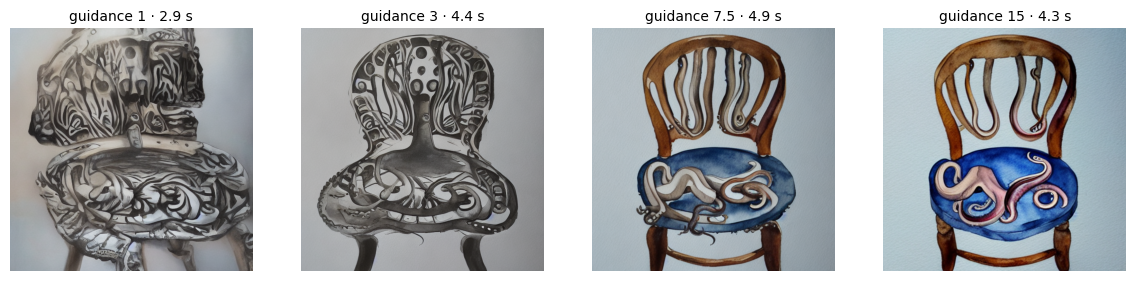

In [15]:
guidances = [1, 3, 7.5, 15]
results = [make_image(prompt, seed=2, guidance=g) for g in guidances]
show_row([r[0] for r in results], [f'guidance {g} · {r[1]:.1f} s' for g, r in zip(guidances, results)])

**Question 2.** Describe the four images: how closely do they follow the prompt, and how do colours and details change? Compare with Lab Part 2

Your answer:

* Guidance 1: The image is quite chaotic, abstract, and fails to clearly represent a recognizable "chair that looks like an octopus". The colors are dull and washed out. This matches Lab Part 2 where a guidance of 1 (no amplification) resulted in an output that barely aligns with the conditional text.
* Guidance 3: The structure starts to emerge. We can see a chair shape and tentacle features, but the details are still somewhat soft and the watercolor styling is quiet muted.
* Guidance 7.5 (Default): This image represents the best balance. The prompt is closely followed (a very clear chair made of defined tentacles), the watercolor aesthetic is well defined with beautiful pigment stains, and the overall composition looks natural.
* Guidance 15: The details are extremely sharp, but the colors are heavily over-saturated, with deep, dark outlines and very high contrast. The watercolor effect becomes less painterly and more harsh, similar to the over-saturated, high-contrast artifacts seen at extreme guidance levels in Lab Part 2.


**Question 3.** Look at the generation times. Why is guidance 1 faster than the other values? (Hint: how many times is the network asked at each step?)

Your answer:

* Why guidance 1 is faster: At each denoising step, classifier-free guidance usually requires computing **two predictions** from the UNet network: one conditioned on the prompt, and one unconditioned (using an empty prompt `""`). These two predictions are then combined to amplify the prompt's direction.
* The difference with guidance 1: When the guidance scale is set to `1` (or less), the unconditioned prediction is not needed because there is no prompt amplification. Therefore, the network is only asked **1 time per step** instead of **2 times per step**, cutting the neural network evaluation time in half and making the overall generation significantly faster.


## 4 · Change only the number of steps



Same prompt, same seed, same guidance; 5, 10, 25 and 50 steps.

**Predict.** Using what you saw in Lab part 1, what will happen with 5 steps? How will the time change?

**Your answer:**

* With only 5 steps, I’d expect the image to be rougher and less detailed, and it may follow the prompt less accurately. It should generate faster than with 10, 25, or 50 steps because the model performs fewer denoising steps.

Potential NSFW content was detected in one or more images. A black image will be returned instead. Try again with a different prompt and/or seed.


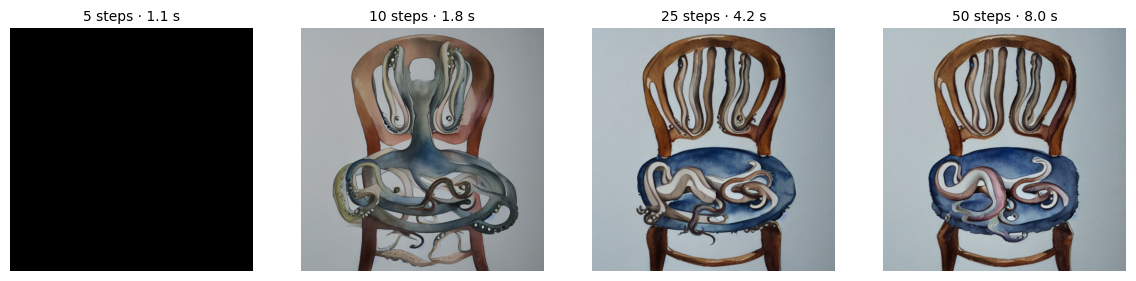

In [16]:
step_counts = [5, 10, 25, 50]
results = [make_image(prompt, seed=2, steps=n) for n in step_counts]
show_row([r[0] for r in results], [f'{n} steps · {r[1]:.1f} s' for n, r in zip(step_counts, results)])

**Question 4.** How do the image quality and the time change with the number of steps? From which number of steps do you stop seeing a clear improvement?

**Your answer:**

* As the number of steps increases, the image generally becomes clearer, but generation takes longer. I’d say the improvement becomes less noticeable after about 25 steps; going from 25 to 50 takes longer for only a small quality gain.

## 5 · With or without randomness


We generate four images from **the same seed** (the same starting noise):

- two **without** randomness (DDIM style);
- two **with** randomness (DDPM style), using a different fresh noise each time.

**Predict.** Which images will be identical?

**Your answer:**

* The two images generated without randomness should be identical, since they start from the same noise and follow the same steps. The two generated with randomness will likely differ because each gets fresh noise during generation.

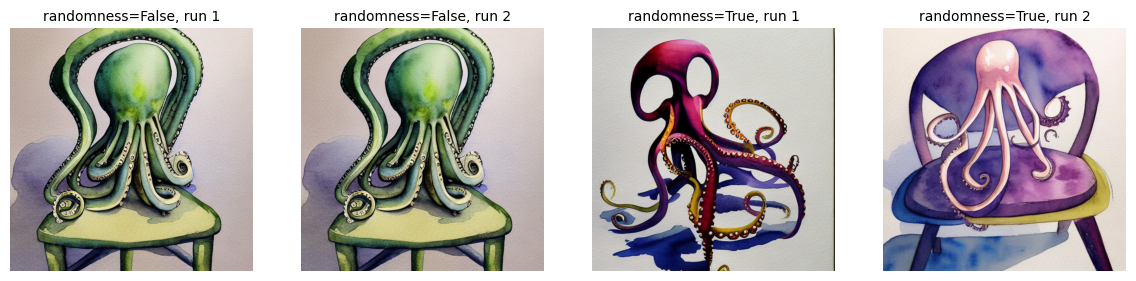

In [17]:
images, titles = [], []
for randomness in [False, True]:
    for run in [1, 2]:
        image, _ = make_image(prompt, seed=3, randomness=randomness, randomness_seed=run)
        images.append(image)
        titles.append(f'randomness={randomness}, run {run}')
show_row(images, titles)

**Question 5.** Which images are identical, and why?

**Your answer:**

* The two images generated without randomness (DDIM) are identical: same starting noise, same deterministic steps. The two with randomness (DDPM) differ because fresh noise is added during each run.




## 6 · Add a negative prompt


With a negative prompt, the answer **without prompt** of classifier-free guidance is replaced by the answer for the negative prompt, so the guidance pushes **away** from it. To see the effect clearly, we use a new prompt and ask the model to avoid grapes, on four seeds.

**Predict.** Will the grapes disappear from all four images?

**Your answer:**

* I’d expect the negative prompt to reduce or remove grapes in most images, but not necessarily all four. The result can vary with the starting seed, and the model may not follow the instruction perfectly.


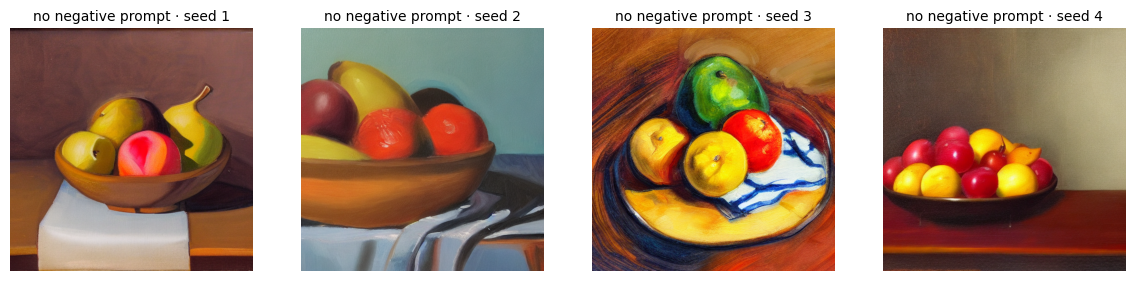

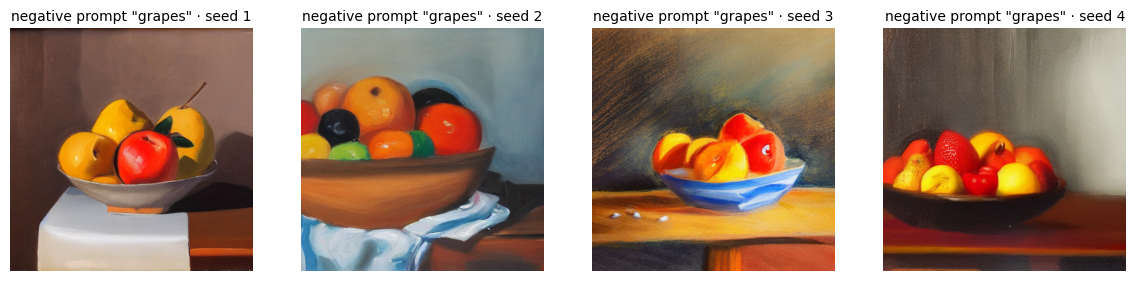

In [18]:
fruit_prompt = 'a bowl of fruit on a wooden table, still life painting'
seeds = [1, 2, 3, 4]
without = [make_image(fruit_prompt, seed=s)[0] for s in seeds]
with_negative = [make_image(fruit_prompt, seed=s, negative_prompt='grapes')[0] for s in seeds]
show_row(without, [f'no negative prompt · seed {s}' for s in seeds])
show_row(with_negative, [f'negative prompt "grapes" · seed {s}' for s in seeds])

**Question 6.** What did the negative prompt change? Did it remove grapes every time?

**Your answer:**

* The negative prompt reduced or removed the grapes, but it did not remove them in every image. Its effect varied across the four seeds.

## 7 · Look inside: the latent space



Stable Diffusion does not remove noise from the 512 × 512 pixels directly. The whole generation loop happens on a much smaller **latent** image, and only at the end does the **decoder** of the autoencoder (Lecture 2) turn it into pixels.

We ask the pipeline to stop before the decoder and give us the latent.

Shape of the latent: (4, 64, 64) (channels, height, width)
Values in the image: 786,432 · values in the latent: 16,384 · ratio: 48x


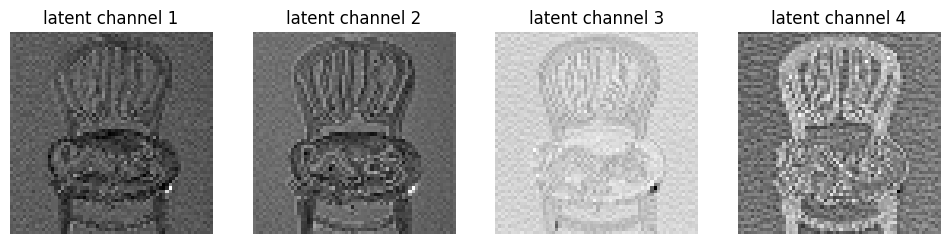

In [19]:
latent = pipe(prompt, num_inference_steps=25, guidance_scale=7.5, latents=starting_noise(2), output_type='latent').images
image_size = LATENT_SIZE * pipe.vae_scale_factor                 # 512 pixels for Stable Diffusion 1.5
image_values = image_size * image_size * 3                        # 3 colour channels
latent_values = latent[0].numel()
print('Shape of the latent:', tuple(latent.shape[1:]), '(channels, height, width)')
print(f'Values in the image: {image_values:,} · values in the latent: {latent_values:,} · ratio: {image_values / latent_values:.0f}x')

fig, axes = plt.subplots(1, latent.shape[1], figsize=(3 * latent.shape[1], 3.3))
for c, ax in enumerate(axes):
    ax.imshow(latent[0, c].float().cpu(), cmap='gray')
    ax.set_title(f'latent channel {c + 1}')
    ax.axis('off')
plt.show()

Now we decode this latent with the decoder of the autoencoder.

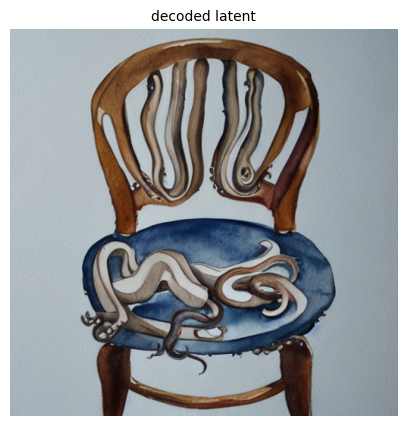

In [20]:
with torch.no_grad():
    decoded = pipe.vae.decode(latent / pipe.vae.config.scaling_factor).sample
decoded_image = pipe.image_processor.postprocess(decoded, output_type='pil')[0]
show_row([decoded_image], ['decoded latent'], size=5)

**Question 7.** How many times fewer values does the generation loop work on?  Can you recognise the image in the latent channels? Why is working in the latent space useful?

**Your answer:**

* For a 512 × 512 RGB image, the loop works on a latent of 4 × 64 × 64 values: 48 times fewer. The individual latent channels don’t look like a recognizable image;
they encode features that the decoder combines to reconstruct it. Working in latent space is useful because it reduces computation and memory, making generation faster.

## 8 · Watch the image appear


We save the latent at a few steps of a 25-step generation and decode each of them, to see the current state of the image during the generation.

**Predict.** As in Lab part 2, what will appear first?

**Your answer:**

* As in Lab part 2, I’d expect the overall shapes and main composition to appear first. Fine details and sharper textures should emerge later.


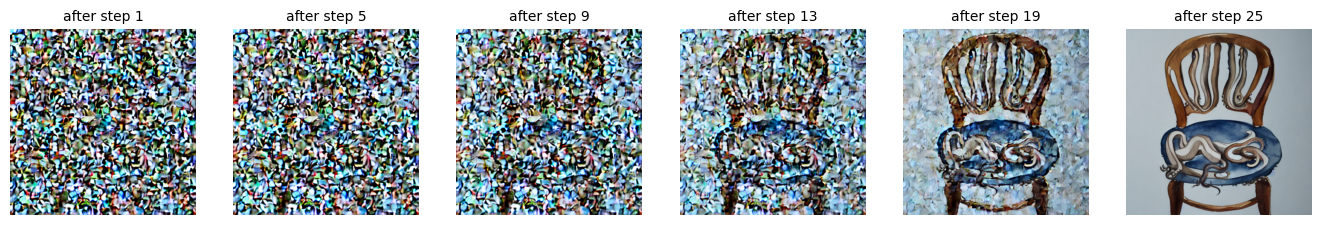

In [21]:
SAVE_AT = [0, 4, 8, 12, 18, 24]
saved = {}

def remember(pipeline, step_index, timestep, callback_kwargs):
    if step_index in SAVE_AT:
        saved[step_index] = callback_kwargs['latents'].clone()
    return callback_kwargs

pipe(prompt, num_inference_steps=25, guidance_scale=7.5, latents=starting_noise(2),
     callback_on_step_end=remember, callback_on_step_end_tensor_inputs=['latents'])

frames = []
with torch.no_grad():
    for k in SAVE_AT:
        decoded = pipe.vae.decode(saved[k] / pipe.vae.config.scaling_factor).sample
        frames.append(pipe.image_processor.postprocess(decoded, output_type='pil')[0])
show_row(frames, [f'after step {k + 1}' for k in SAVE_AT], size=2.8)

**Question 8.** What appears first, and what appears last? Is it the same as with the digits of Lab part 2?

**Your answer:**

* The chair’s overall shape and composition emerge first, followed by details such as the wood, fabric, and texture. Yes, this is similar to the digits in Lab part 2: both start with broad shapes and become more detailed as denoising progresses.

## 9 · Your turn


Choose a prompt of your own (for example a landscape, an object or a scene in a given painting style). Then:

1. Generate it with the default settings.
2. Choose **one** setting to improve the result (seed, guidance, number of steps or negative prompt), and change only that setting.
3. Keep the image you prefer.

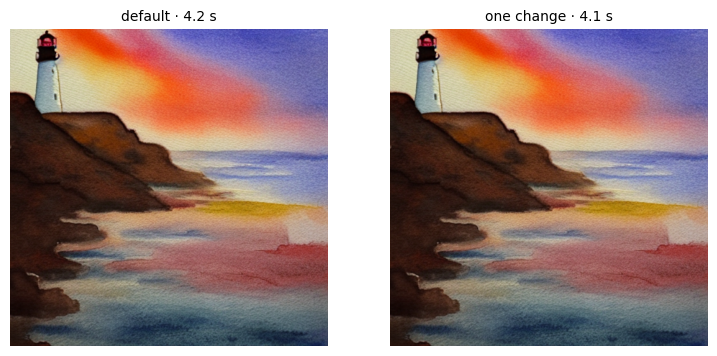

In [22]:
my_prompt = 'a lighthouse on a cliff at sunset, watercolor'   # write your own prompt here

image_a, time_a = make_image(my_prompt, seed=0)
image_b, time_b = make_image(my_prompt, seed=0, guidance=7.5, steps=25)   # change ONE setting in this line
show_row([image_a, image_b], [f'default · {time_a:.1f} s', f'one change · {time_b:.1f} s'], size=4.5)

**Question 9.** Which setting did you change, why, and what was the effect? Was it worth the extra (or saved) time?

**Your answer:**

* I changed the number of steps to make generation faster. With fewer steps, the image appeared more quickly but was less detailed. The time saved was worth it when the quality difference was small.


## 10 · Final questions

Answer in a few sentences, using what you saw in the three labs. No formulas are needed.

**Final question 1.** Why is it easier for a network to remove a little noise than to remove all of it at once?

**Your answer:**

* t’s easier to remove noise gradually because each step is a smaller, more manageable correction. The network can repeatedly refine the image, using the structure revealed at each step, instead of trying to recover everything from pure noise at once.

**Final question 2.** When the noise level is high, the network predicts an "average" answer. Why do the generated images still end up sharp and not blurry?

**Your answer:**

* The average prediction at high noise is only an early step. As noise is gradually removed, the image becomes clearer, and the network can distinguish its features better. Later steps refine the image, so it ends up sharp rather than staying blurry.

**Final question 3.** What do you gain and what do you lose when you reduce the number of steps?

**Your answer:**

* Reducing the number of steps makes generation faster, but the image may lose detail, look less clear, or match the prompt less accurately.

**Final question 4.** Explain classifier-free guidance in your own words: what is computed at each step, and what happens when the guidance strength is very high?

**Your answer:**

* At each step, the model predicts the noise twice: once using the text prompt and once without it. Guidance amplifies the difference between those predictions to steer the image toward the prompt. If guidance is too strong, the image may look exaggerated or distorted.

**Final question 5.** Why does Stable Diffusion work on a latent image instead of the pixels? What is the price of this choice? (See slide 49, *Compression buys speed, but it can lose detail*.)

**Your answer:**

* Stable Diffusion uses a compressed latent image because it has far fewer values than the full pixel image, making generation faster and less computationally demanding. The cost is that compression can discard fine details, so some details may be blurred or missing.